# Lab 4 : Auto-encodeurs, VAE et GANs (IA générative)

**Module :** Deep Learning, cycle LSI, FST Tanger
**Outils :** PyTorch, Google Colab (GPU Tesla T4)

## Objectif
Se familiariser avec PyTorch et construire des architectures d'IA générative : auto-encodeur (AE), auto-encodeur variationnel (VAE) et réseaux antagonistes génératifs (GAN).

## Plan du notebook
- **0. Configuration** : GPU, imports, chargement de MNIST
- **Partie 1 : AE et VAE sur MNIST** (dataset MNIST)
  - 1. Auto-encodeur : architecture, entraînement, hyperparamètres, évaluation
  - 2. VAE : architecture, entraînement, hyperparamètres, évaluation
  - 3. Comparaison AE vs VAE (loss, KL divergence)
  - 4. Visualisation de l'espace latent
- **Partie 2 : GAN sur Abstract Art Gallery**
  - 5. Données, 6. Modèles (générateur, discriminateur, perte, optimiseurs), 7. Entraînement, 8. Évaluation et génération
- **Synthèse personnelle**

# 0. Configuration de l'environnement
## 0.1 Vérification du GPU

In [1]:
# vérifier le GPU
import torch
print("PyTorch :", torch.__version__)
print("GPU dispo :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Carte :", torch.cuda.get_device_name(0))

PyTorch : 2.14.1+cu130
GPU dispo : True
Carte : Tesla T4


## 0.2 Imports et chargement du dataset MNIST

In [2]:
# imports et chargement de MNIST
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

tf = transforms.ToTensor()   # convertit les images en tenseurs avec des pixels dans [0,1]
train_ds = datasets.MNIST("data", train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST("data", train=False, download=True, transform=tf)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=128)

print("Train :", len(train_ds), "images | Test :", len(test_ds), "images")

Train : 60000 images | Test : 10000 images


## 0.3 Exploration des données

Forme d'un batch : torch.Size([128, 1, 28, 28])


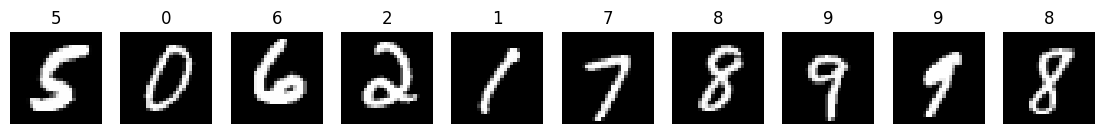

In [3]:
# regarder les données
x, y = next(iter(train_dl))
print("Forme d'un batch :", x.shape)   # [128, 1, 28, 28]

fig, ax = plt.subplots(1, 10, figsize=(14, 2))
for i in range(10):
    ax[i].imshow(x[i, 0], cmap="gray")
    ax[i].set_title(int(y[i]))
    ax[i].axis("off")
plt.show()

# Partie 1 : Auto-encodeur (AE) et Auto-encodeur variationnel (VAE)
# 1. Auto-encodeur (AE)
## 1.1 Architecture
Un auto-encodeur apprend à **compresser** puis **reconstruire** ses entrées :
- **Encodeur** : image (784 pixels) → vecteur latent `z` de petite dimension (couches 784 → 256 → 64 → `latent`)
- **Décodeur** : `z` → image reconstruite (couches `latent` → 64 → 256 → 784)
- Activation **ReLU** dans les couches cachées et **Sigmoid** en sortie pour obtenir des pixels dans [0, 1]

On commence avec `latent=2` pour pouvoir visualiser l'espace latent plus loin.

In [4]:
# Définir l'auto-encoder
class AE(nn.Module):
    def __init__(self, latent=2):
        super().__init__()
        # Encodeur : image 784 pixels -> vecteur de 'latent' nombres
        self.enc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 64),  nn.ReLU(),
            nn.Linear(64, latent))
        # Décodeur : vecteur latent -> image 784 pixels
        self.dec = nn.Sequential(
            nn.Linear(latent, 64),  nn.ReLU(),
            nn.Linear(64, 256),     nn.ReLU(),
            nn.Linear(256, 784),    nn.Sigmoid())   # Sigmoid : sortie entre 0 et 1, comme les pixels

    def forward(self, x):
        z = self.enc(x)                          # compression
        x_rec = self.dec(z).view(-1, 1, 28, 28)  # reconstruction
        return x_rec, z

ae = AE(latent=2).to(device)
print(ae)
print("Nombre de paramètres :", sum(p.numel() for p in ae.parameters()))

AE(
  (enc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
  (dec): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)
Nombre de paramètres : 435858


## 1.2 Entraînement de l'AE (configuration initiale)
- **Fonction de perte** : MSE (erreur quadratique moyenne) entre l'image originale et sa reconstruction
- **Optimiseur** : Adam, learning rate = 1e-3
- **Epochs** : 20, **batch size** : 128

À chaque epoch, on mesure aussi la loss sur le jeu de test (sans mise à jour des poids) pour détecter un éventuel sur-apprentissage.

In [5]:
# Entraîner l'auto-encoder
def train_ae(model, epochs=20, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr, te = [], []
    for ep in range(epochs):
        # --- entraînement ---
        model.train(); tot = 0
        for x, _ in train_dl:
            x = x.to(device)
            x_rec, _ = model(x)
            loss = F.mse_loss(x_rec, x)      # erreur entre original et reconstruction
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0)
        tr.append(tot / len(train_ds))

        # --- évaluation sur le test (sans apprendre) ---
        model.eval(); tot = 0
        with torch.no_grad():
            for x, _ in test_dl:
                x = x.to(device)
                x_rec, _ = model(x)
                tot += F.mse_loss(x_rec, x).item() * x.size(0)
        te.append(tot / len(test_ds))
        print(f"Epoch {ep+1:2d}/{epochs} | train loss {tr[-1]:.4f} | test loss {te[-1]:.4f}")
    return tr, te

ae_tr, ae_te = train_ae(ae, epochs=20, lr=1e-3)

Epoch  1/20 | train loss 0.0615 | test loss 0.0513
Epoch  2/20 | train loss 0.0493 | test loss 0.0473
Epoch  3/20 | train loss 0.0457 | test loss 0.0447
Epoch  4/20 | train loss 0.0438 | test loss 0.0430
Epoch  5/20 | train loss 0.0425 | test loss 0.0422
Epoch  6/20 | train loss 0.0415 | test loss 0.0414
Epoch  7/20 | train loss 0.0408 | test loss 0.0406
Epoch  8/20 | train loss 0.0401 | test loss 0.0404
Epoch  9/20 | train loss 0.0396 | test loss 0.0396
Epoch 10/20 | train loss 0.0392 | test loss 0.0393
Epoch 11/20 | train loss 0.0388 | test loss 0.0391
Epoch 12/20 | train loss 0.0384 | test loss 0.0388
Epoch 13/20 | train loss 0.0381 | test loss 0.0383
Epoch 14/20 | train loss 0.0378 | test loss 0.0381
Epoch 15/20 | train loss 0.0377 | test loss 0.0381
Epoch 16/20 | train loss 0.0374 | test loss 0.0379
Epoch 17/20 | train loss 0.0373 | test loss 0.0377
Epoch 18/20 | train loss 0.0371 | test loss 0.0376
Epoch 19/20 | train loss 0.0369 | test loss 0.0374
Epoch 20/20 | train loss 0.0367

## 1.3 Évaluation de l'AE : courbe de loss et reconstructions

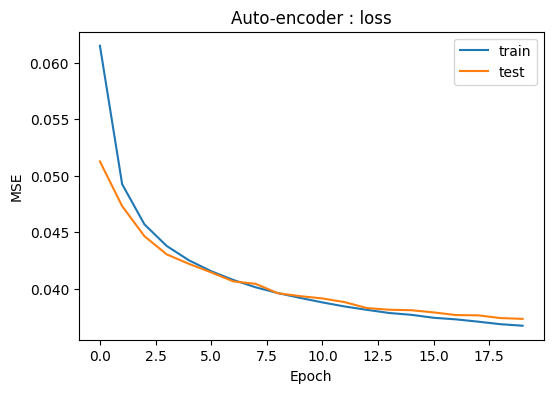

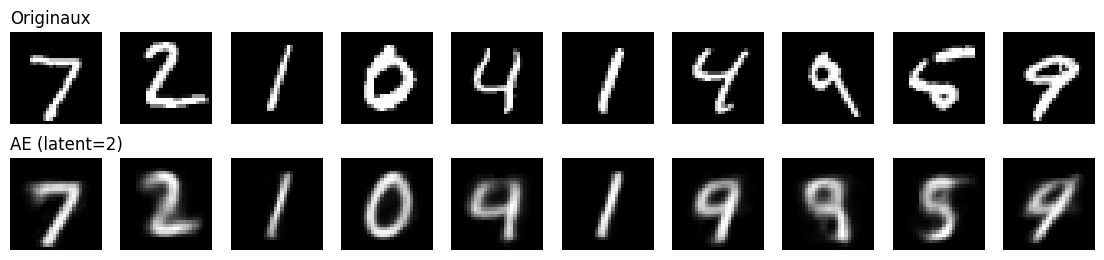

In [6]:
# Courbe de loss
plt.figure(figsize=(6,4))
plt.plot(ae_tr, label="train"); plt.plot(ae_te, label="test")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Auto-encoder : loss"); plt.legend()
plt.savefig("curve_ae.png", dpi=150); plt.show()

# Reconstructions : ligne 1 = originaux, ligne 2 = reconstruits par l'AE
x, _ = next(iter(test_dl)); x = x[:10].to(device)
ae.eval()
with torch.no_grad():
    x_rec, _ = ae(x)

fig, ax = plt.subplots(2, 10, figsize=(14, 3))
for i in range(10):
    ax[0, i].imshow(x[i, 0].cpu(), cmap="gray");     ax[0, i].axis("off")
    ax[1, i].imshow(x_rec[i, 0].cpu(), cmap="gray"); ax[1, i].axis("off")
ax[0, 0].set_title("Originaux", loc="left"); ax[1, 0].set_title("AE (latent=2)", loc="left")
plt.savefig("reconstruction_ae.png", dpi=150); plt.show()

**Observations**
- La loss diminue régulièrement (train : 0.0615 → 0.0367) et les courbes train et test sont superposées : **pas de sur-apprentissage**.
- Les chiffres simples (7, 2, 1, 0) sont bien reconstruits, mais les chiffres proches (4, 9, 5) sont tous reconstruits en « 9 » flou.
- Cause : avec `latent=2`, toute l'information d'une image est résumée en 2 nombres, ce qui est insuffisant. La dimension latente est le facteur limitant.

## 1.4 Recherche des meilleurs hyperparamètres de l'AE
On compare plusieurs configurations (dimension latente, learning rate) avec 10 epochs chacune, en regardant la loss de test.

In [7]:
# Chercher les meilleurs hyperparamètres
import io, contextlib

configs = [(2, 1e-3), (8, 1e-3), (16, 1e-3), (16, 1e-2), (16, 1e-4)]   # (dimension latente, learning rate)
results = []
for latent, lr in configs:
    m = AE(latent=latent).to(device)
    with contextlib.redirect_stdout(io.StringIO()):     # masque les prints par epoch
        tr, te = train_ae(m, epochs=10, lr=lr)
    results.append((latent, lr, tr[-1], te[-1]))
    print(f"latent={latent:2d} | lr={lr:.0e} | train {tr[-1]:.4f} | test {te[-1]:.4f}")

latent= 2 | lr=1e-03 | train 0.0386 | test 0.0387
latent= 8 | lr=1e-03 | train 0.0192 | test 0.0190
latent=16 | lr=1e-03 | train 0.0129 | test 0.0124
latent=16 | lr=1e-02 | train 0.0139 | test 0.0140
latent=16 | lr=1e-04 | train 0.0263 | test 0.0254


| Dimension latente | Learning rate | Loss test (10 epochs) |
|---|---|---|
| 2 | 1e-3 | 0.0387 |
| 8 | 1e-3 | 0.0190 |
| 16 | 1e-3 | **0.0124** |
| 16 | 1e-2 | 0.0140 |
| 16 | 1e-4 | 0.0254 |

**Conclusion**
- La **dimension latente** est le paramètre le plus influent : passer de 2 à 16 divise la loss par plus de 3 (0.0387 → 0.0124).
- **Learning rate** : 1e-4 est trop faible pour converger en 10 epochs (0.0254). 1e-2 (0.0140) est un peu moins bon que 1e-3 (0.0124), car trop grand il rend l'entraînement moins précis.
- **Choix retenu : `latent=16`, `lr=1e-3`**, la meilleure configuration testée.

## 1.5 AE final (latent=16, lr=1e-3) et comparaison avec latent=2

Epoch  1/20 | train loss 0.0510 | test loss 0.0293
Epoch  2/20 | train loss 0.0250 | test loss 0.0215
Epoch  3/20 | train loss 0.0202 | test loss 0.0184
Epoch  4/20 | train loss 0.0177 | test loss 0.0163
Epoch  5/20 | train loss 0.0160 | test loss 0.0152
Epoch  6/20 | train loss 0.0149 | test loss 0.0143
Epoch  7/20 | train loss 0.0141 | test loss 0.0134
Epoch  8/20 | train loss 0.0133 | test loss 0.0128
Epoch  9/20 | train loss 0.0127 | test loss 0.0123
Epoch 10/20 | train loss 0.0123 | test loss 0.0119
Epoch 11/20 | train loss 0.0119 | test loss 0.0116
Epoch 12/20 | train loss 0.0116 | test loss 0.0114
Epoch 13/20 | train loss 0.0114 | test loss 0.0112
Epoch 14/20 | train loss 0.0111 | test loss 0.0109
Epoch 15/20 | train loss 0.0109 | test loss 0.0108
Epoch 16/20 | train loss 0.0107 | test loss 0.0107
Epoch 17/20 | train loss 0.0106 | test loss 0.0107
Epoch 18/20 | train loss 0.0104 | test loss 0.0104
Epoch 19/20 | train loss 0.0103 | test loss 0.0104
Epoch 20/20 | train loss 0.0102

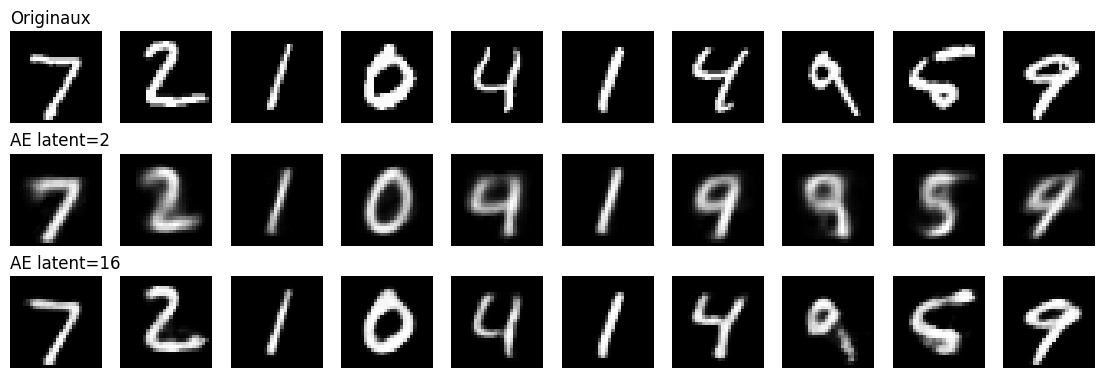

In [8]:
# Entraîner l'AE final et comparer
# AE final : latent=16, lr=1e-3, 20 epochs
ae16 = AE(latent=16).to(device)
ae16_tr, ae16_te = train_ae(ae16, epochs=20, lr=1e-3)

# Comparaison des reconstructions : originaux / AE latent=2 / AE latent=16
x, _ = next(iter(test_dl)); x = x[:10].to(device)
ae.eval(); ae16.eval()
with torch.no_grad():
    r2, _  = ae(x)
    r16, _ = ae16(x)

fig, ax = plt.subplots(3, 10, figsize=(14, 4.5))
for i in range(10):
    for row, img in enumerate([x, r2, r16]):
        ax[row, i].imshow(img[i, 0].cpu(), cmap="gray"); ax[row, i].axis("off")
ax[0, 0].set_title("Originaux", loc="left")
ax[1, 0].set_title("AE latent=2", loc="left")
ax[2, 0].set_title("AE latent=16", loc="left")
plt.savefig("reconstruction_ae_comparaison.png", dpi=150); plt.show()

**Observations**
- Loss de test finale de l'AE à 16 dimensions : **0.0103**, contre ~0.037 pour `latent=2`.
- Les chiffres 4, 9 et 5, confondus avec `latent=2`, sont maintenant bien distingués.
- Un espace latent plus grand conserve plus d'information, mais il ne peut plus être tracé directement. Pour la visualisation de l'espace latent, on utilisera les modèles à `latent=2`.

---
# 2. Auto-encodeur variationnel (VAE)
## 2.1 Architecture et fonction de perte
Le VAE se distingue de l'AE par trois points :
1. L'encodeur produit **une distribution** et non un point : un vecteur de moyennes `mu` et un vecteur de log-variances `logvar`.
2. **Astuce de reparamétrisation** : `z = mu + sigma × ε` avec `ε ~ N(0,1)`. Elle rend l'échantillonnage dérivable, donc l'apprentissage possible.
3. La **loss** a deux termes : `reconstruction + β × KL`.
   - *Reconstruction* (entropie croisée binaire) : l'image reconstruite doit ressembler à l'originale.
   - *KL divergence* : force la distribution latente à rester proche de N(0,1), ce qui permet ensuite de **générer** de nouvelles images en tirant `z` au hasard.

In [9]:
# Définir le VAE
class VAE(nn.Module):
    def __init__(self, latent=2):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 64),  nn.ReLU())
        self.fc_mu     = nn.Linear(64, latent)   # moyenne
        self.fc_logvar = nn.Linear(64, latent)   # log-variance
        self.dec = nn.Sequential(
            nn.Linear(latent, 64),  nn.ReLU(),
            nn.Linear(64, 256),     nn.ReLU(),
            nn.Linear(256, 784),    nn.Sigmoid())

    def reparametrize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)              # bruit N(0,1)
        return mu + std * eps

    def forward(self, x):
        h = self.enc(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = self.reparametrize(mu, logvar)
        return self.dec(z).view(-1, 1, 28, 28), mu, logvar

def vae_loss(x_rec, x, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy(x_rec, x, reduction="sum")                # reconstruction
    kl  = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())          # KL divergence
    return rec + beta * kl, rec, kl

vae = VAE(latent=2).to(device)
print("Nombre de paramètres :", sum(p.numel() for p in vae.parameters()))

Nombre de paramètres : 435988


## 2.2 Entraînement du VAE (configuration initiale)
- Optimiseur Adam, learning rate = 1e-3, 20 epochs, batch size 128, β = 1, `latent=2`
- On suit séparément la loss totale, la reconstruction et la KL divergence, sur le train et le test.
- Les valeurs sont des sommes par image (sur 784 pixels) : elles ne sont pas comparables aux MSE de l'AE.

In [10]:
# Entraîner le VAE
def train_vae(model, epochs=20, lr=1e-3, beta=1.0, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"loss": [], "rec": [], "kl": [], "test_loss": [], "test_rec": [], "test_kl": []}
    for ep in range(epochs):
        model.train(); L = R = K = 0
        for x, _ in train_dl:
            x = x.to(device)
            x_rec, mu, lv = model(x)
            loss, rec, kl = vae_loss(x_rec, x, mu, lv, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            L += loss.item(); R += rec.item(); K += kl.item()
        n = len(train_ds)
        h["loss"].append(L/n); h["rec"].append(R/n); h["kl"].append(K/n)

        model.eval(); L = R = K = 0
        with torch.no_grad():
            for x, _ in test_dl:
                x = x.to(device)
                x_rec, mu, lv = model(x)
                loss, rec, kl = vae_loss(x_rec, x, mu, lv, beta)
                L += loss.item(); R += rec.item(); K += kl.item()
        n = len(test_ds)
        h["test_loss"].append(L/n); h["test_rec"].append(R/n); h["test_kl"].append(K/n)
        if verbose:
            print(f"Epoch {ep+1:2d}/{epochs} | loss {h['loss'][-1]:.2f} (rec {h['rec'][-1]:.2f}, KL {h['kl'][-1]:.2f}) | test {h['test_loss'][-1]:.2f}")
    return h

vae_hist = train_vae(vae, epochs=20, lr=1e-3)

Epoch  1/20 | loss 195.67 (rec 192.13, KL 3.54) | test 169.71
Epoch  2/20 | loss 165.67 (rec 160.71, KL 4.96) | test 162.37
Epoch  3/20 | loss 160.32 (rec 155.05, KL 5.27) | test 158.69
Epoch  4/20 | loss 156.84 (rec 151.38, KL 5.46) | test 155.65
Epoch  5/20 | loss 154.50 (rec 148.89, KL 5.62) | test 153.93
Epoch  6/20 | loss 152.78 (rec 147.06, KL 5.71) | test 152.16
Epoch  7/20 | loss 151.37 (rec 145.55, KL 5.83) | test 151.36
Epoch  8/20 | loss 150.15 (rec 144.28, KL 5.87) | test 150.72
Epoch  9/20 | loss 149.41 (rec 143.46, KL 5.94) | test 149.47
Epoch 10/20 | loss 148.48 (rec 142.49, KL 5.99) | test 148.88
Epoch 11/20 | loss 147.72 (rec 141.66, KL 6.06) | test 147.99
Epoch 12/20 | loss 147.06 (rec 140.95, KL 6.11) | test 147.80
Epoch 13/20 | loss 146.52 (rec 140.38, KL 6.14) | test 146.94
Epoch 14/20 | loss 146.02 (rec 139.81, KL 6.21) | test 146.66
Epoch 15/20 | loss 145.41 (rec 139.17, KL 6.24) | test 145.82
Epoch 16/20 | loss 144.86 (rec 138.59, KL 6.27) | test 145.38
Epoch 17

## 2.3 Évaluation du VAE : loss, KL divergence et reconstructions

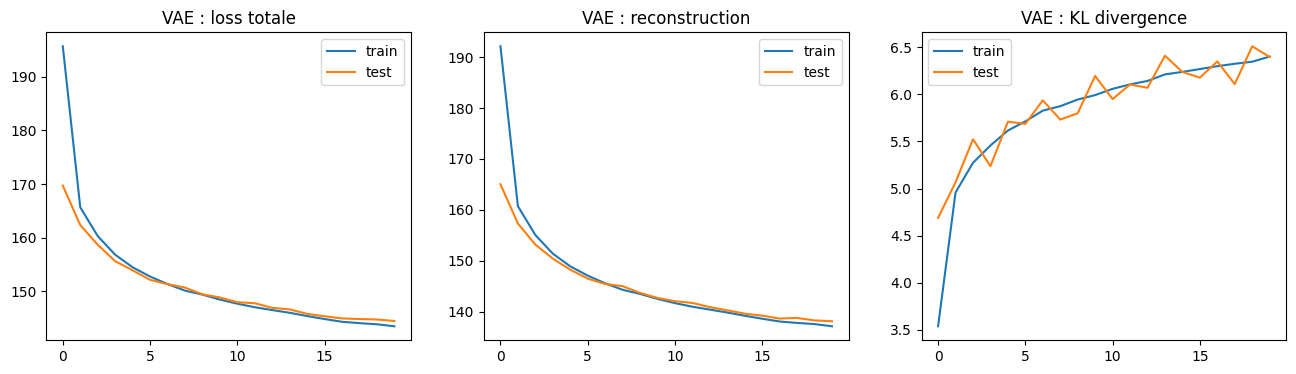

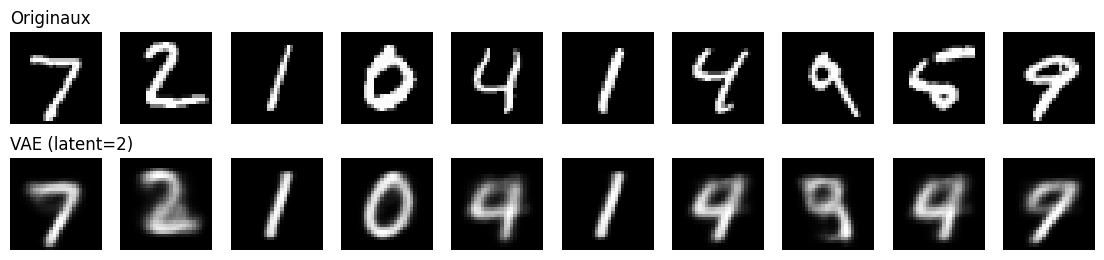

In [11]:
# Courbes et reconstructions du VAE
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(vae_hist["loss"], label="train"); ax[0].plot(vae_hist["test_loss"], label="test")
ax[0].set_title("VAE : loss totale"); ax[0].legend()
ax[1].plot(vae_hist["rec"], label="train"); ax[1].plot(vae_hist["test_rec"], label="test")
ax[1].set_title("VAE : reconstruction"); ax[1].legend()
ax[2].plot(vae_hist["kl"], label="train"); ax[2].plot(vae_hist["test_kl"], label="test")
ax[2].set_title("VAE : KL divergence"); ax[2].legend()
plt.savefig("curves_vae.png", dpi=150); plt.show()

x, _ = next(iter(test_dl)); x = x[:10].to(device)
vae.eval()
with torch.no_grad():
    xv, _, _ = vae(x)
fig, ax = plt.subplots(2, 10, figsize=(14, 3))
for i in range(10):
    ax[0, i].imshow(x[i, 0].cpu(), cmap="gray");  ax[0, i].axis("off")
    ax[1, i].imshow(xv[i, 0].cpu(), cmap="gray"); ax[1, i].axis("off")
ax[0, 0].set_title("Originaux", loc="left"); ax[1, 0].set_title("VAE (latent=2)", loc="left")
plt.savefig("reconstruction_vae.png", dpi=150); plt.show()

**Observations**
- La loss totale et la reconstruction diminuent (reconstruction : 192 → 137), avec des courbes train et test proches : pas de sur-apprentissage.
- La **KL divergence augmente** (3.5 → 6.4) alors que la reconstruction s'améliore. Au début, l'encodeur est proche de N(0,1) mais reconstruit mal. Il apprend ensuite à placer chaque chiffre à un endroit précis de l'espace latent, ce qui « coûte » de la KL. C'est le **compromis reconstruction / régularisation**.
- Les reconstructions sont plus floues que celles de l'AE (effet de la régularisation KL et du bruit injecté dans `z`). Plusieurs chiffres proches sont confondus à cause de `latent=2`.

## 2.4 Recherche des meilleurs hyperparamètres du VAE
On compare plusieurs configurations (dimension latente, learning rate, β) avec 10 epochs chacune.
On compare la **reconstruction de test** (`test rec`) et non la loss totale, car β change le poids de la KL et rend les loss totales non comparables entre elles.

In [12]:
# Chercher les meilleurs hyperparamètres du VAE
configs = [(2, 1e-3, 1.0), (8, 1e-3, 1.0), (16, 1e-3, 1.0),
           (16, 1e-3, 4.0), (16, 1e-2, 1.0)]   # (dimension latente, learning rate, beta)
for latent, lr, beta in configs:
    m = VAE(latent=latent).to(device)
    h = train_vae(m, epochs=10, lr=lr, beta=beta, verbose=False)   # verbose=False : pas de print par epoch
    print(f"latent={latent:2d} | lr={lr:.0e} | beta={beta:.1f} | "
          f"test rec {h['test_rec'][-1]:.2f} | test KL {h['test_kl'][-1]:.2f} | test loss {h['test_loss'][-1]:.2f}")

latent= 2 | lr=1e-03 | beta=1.0 | test rec 141.80 | test KL 6.05 | test loss 147.85
latent= 8 | lr=1e-03 | beta=1.0 | test rec 96.59 | test KL 15.82 | test loss 112.42
latent=16 | lr=1e-03 | beta=1.0 | test rec 90.64 | test KL 18.38 | test loss 109.01
latent=16 | lr=1e-03 | beta=4.0 | test rec 117.18 | test KL 7.83 | test loss 148.51
latent=16 | lr=1e-02 | beta=1.0 | test rec 120.68 | test KL 11.57 | test loss 132.25


| Dimension latente | Learning rate | β | Reconstruction test | KL test | Loss test |
|---|---|---|---|---|---|
| 2 | 1e-3 | 1 | 141.80 | 6.05 | 147.85 |
| 8 | 1e-3 | 1 | 96.59 | 15.82 | 112.42 |
| 16 | 1e-3 | 1 | **90.64** | 18.38 | **109.01** |
| 16 | 1e-3 | 4 | 117.18 | 7.83 | 148.51 |
| 16 | 1e-2 | 1 | 120.68 | 11.57 | 132.25 |

**Conclusion**
- **Dimension latente** : passer de 2 à 16 réduit la reconstruction de 141.8 à 90.6. Le VAE encode plus d'information, donc la KL monte (6.1 → 18.4).
- **β** : avec β = 4, la KL est forcée à 7.8 mais la reconstruction se dégrade (117.2 contre 90.6). Un β élevé régularise davantage et donne des images plus floues. C'est le compromis reconstruction / régularisation.
- **Learning rate** : contrairement à l'AE, 1e-2 est nettement moins bon que 1e-3 pour le VAE (reconstruction 120.7 contre 90.6) : l'entraînement est moins stable.
- **Choix retenu : `latent=16`, `lr=1e-3`, `β=1`**, meilleure reconstruction et meilleure loss de test. Pour la visualisation de l'espace latent, on garde le VAE à `latent=2`.

## 2.5 VAE final (latent=16, lr=1e-3, β=1) et comparaison avec l'AE
On entraîne le VAE avec les meilleurs hyperparamètres pendant 20 epochs, puis on compare ses reconstructions à celles de l'AE (latent=16) et on génère de nouveaux chiffres en tirant `z` dans N(0,1).

Epoch  1/20 | loss 195.67 (rec 189.94, KL 5.72) | test 156.64
Epoch  2/20 | loss 143.63 (rec 130.41, KL 13.22) | test 132.67
Epoch  3/20 | loss 128.53 (rec 113.11, KL 15.42) | test 123.03
Epoch  4/20 | loss 121.36 (rec 105.01, KL 16.35) | test 117.77
Epoch  5/20 | loss 117.65 (rec 100.71, KL 16.94) | test 115.27
Epoch  6/20 | loss 115.21 (rec 97.84, KL 17.37) | test 113.43
Epoch  7/20 | loss 113.45 (rec 95.72, KL 17.74) | test 112.13
Epoch  8/20 | loss 112.05 (rec 94.08, KL 17.97) | test 110.85
Epoch  9/20 | loss 110.95 (rec 92.79, KL 18.16) | test 109.96
Epoch 10/20 | loss 110.13 (rec 91.78, KL 18.35) | test 109.21
Epoch 11/20 | loss 109.37 (rec 90.91, KL 18.46) | test 108.66
Epoch 12/20 | loss 108.81 (rec 90.23, KL 18.58) | test 108.24
Epoch 13/20 | loss 108.21 (rec 89.59, KL 18.62) | test 107.52
Epoch 14/20 | loss 107.76 (rec 89.03, KL 18.73) | test 107.41
Epoch 15/20 | loss 107.41 (rec 88.59, KL 18.82) | test 106.81
Epoch 16/20 | loss 107.00 (rec 88.15, KL 18.84) | test 106.73
Epoc

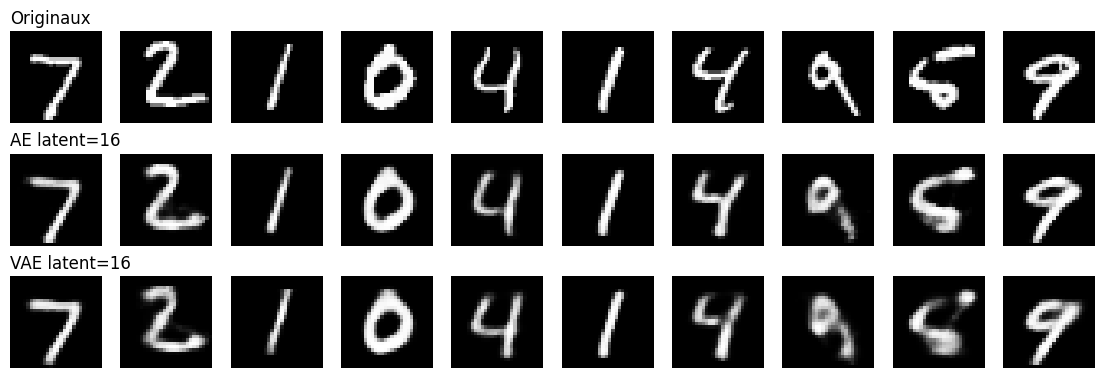

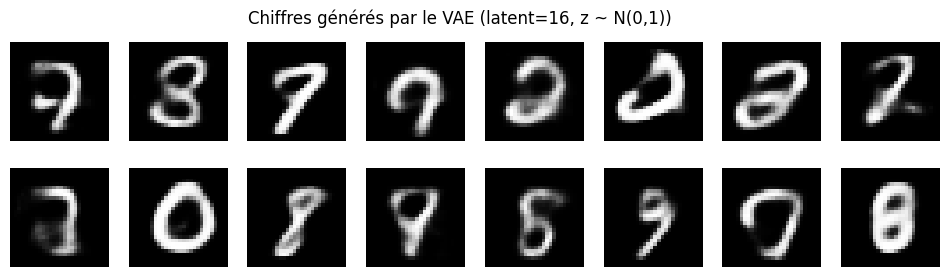

In [13]:
# VAE final : latent=16, lr=1e-3, beta=1, 20 epochs
vae16 = VAE(latent=16).to(device)
vae16_hist = train_vae(vae16, epochs=20, lr=1e-3, beta=1.0)

# Reconstructions : originaux / AE latent=16 / VAE latent=16
x, _ = next(iter(test_dl)); x = x[:10].to(device)
ae16.eval(); vae16.eval()
with torch.no_grad():
    ra, _     = ae16(x)
    rv, _, _  = vae16(x)

fig, ax = plt.subplots(3, 10, figsize=(14, 4.5))
for i in range(10):
    for row, img in enumerate([x, ra, rv]):
        ax[row, i].imshow(img[i, 0].cpu(), cmap="gray"); ax[row, i].axis("off")
ax[0, 0].set_title("Originaux", loc="left")
ax[1, 0].set_title("AE latent=16", loc="left")
ax[2, 0].set_title("VAE latent=16", loc="left")
plt.savefig("reconstruction_ae_vae_16.png", dpi=150); plt.show()

# Génération : 16 chiffres tirés dans N(0,1) (espace latent à 16 dimensions)
with torch.no_grad():
    gen16 = vae16.dec(torch.randn(16, 16, device=device)).view(-1, 28, 28).cpu()
fig, ax = plt.subplots(2, 8, figsize=(12, 3))
for i, a in enumerate(ax.flat):
    a.imshow(gen16[i], cmap="gray"); a.axis("off")
plt.suptitle("Chiffres générés par le VAE (latent=16, z ~ N(0,1))")
plt.savefig("vae16_generation.png", dpi=150); plt.show()

**Observations**
- Le VAE à 16 dimensions atteint une loss de test de **105.82** (reconstruction ≈ 87, KL ≈ 19), contre 144.50 pour `latent=2`.
- **AE vs VAE** : l'AE reconstruit un peu plus fidèlement (contours plus nets). Le VAE donne des images légèrement plus floues et rate plus souvent les chiffres ambigus (le 9 et le 5 de la ligne du bas sont déformés). C'est le prix de la régularisation KL.
- **Génération** : les chiffres tirés au hasard dans N(0,1) sont en partie lisibles (7, 8, 2, 0, 9, 5…), mais plusieurs sont ambigus ou mal formés. Ces chiffres n'existent pas dans MNIST : le VAE est un vrai modèle génératif, alors que l'AE ne peut pas générer proprement, car son espace latent n'est pas régularisé.

# 3. Comparaison AE vs VAE
On compare les deux modèles à la même dimension latente (16) : courbes de loss et qualité des reconstructions.
Les valeurs de loss ne sont pas comparables directement (MSE pour l'AE, BCE + KL sommées pour le VAE) ; on compare donc surtout la qualité visuelle.

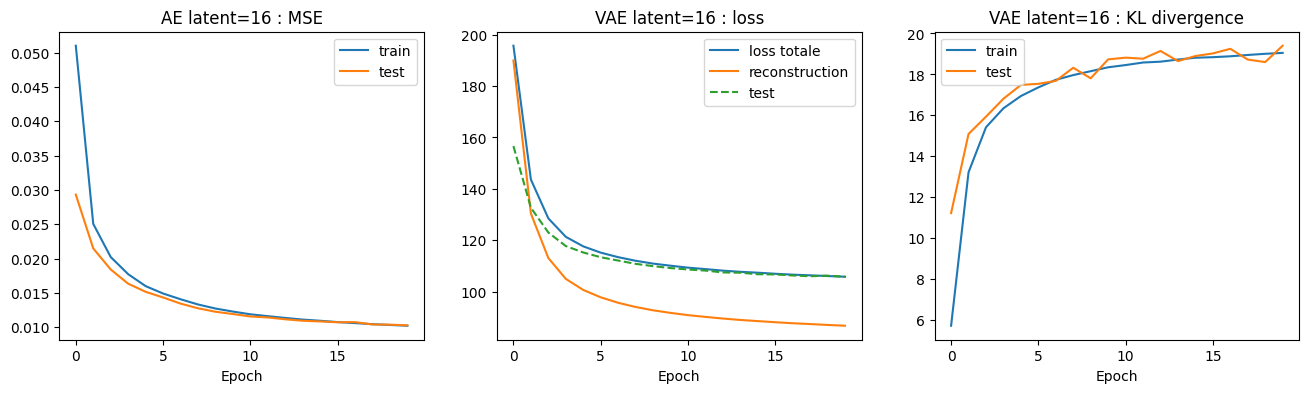

In [14]:
# Courbes finales : AE (MSE) et VAE (loss, reconstruction, KL), latent=16
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ae16_tr, label="train"); ax[0].plot(ae16_te, label="test")
ax[0].set_title("AE latent=16 : MSE"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(vae16_hist["loss"], label="loss totale"); ax[1].plot(vae16_hist["rec"], label="reconstruction")
ax[1].plot(vae16_hist["test_loss"], "--", label="test")
ax[1].set_title("VAE latent=16 : loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
ax[2].plot(vae16_hist["kl"], label="train"); ax[2].plot(vae16_hist["test_kl"], label="test")
ax[2].set_title("VAE latent=16 : KL divergence"); ax[2].set_xlabel("Epoch"); ax[2].legend()
plt.savefig("curves_ae_vae_16.png", dpi=150); plt.show()

**Observations (courbes)**
- **AE** : la MSE passe d'environ 0.051 à 0.010 et se stabilise. Les courbes train et test se superposent à la fin : pas de sur-apprentissage. Le test est sous le train au début, car la loss d'entraînement est une moyenne calculée pendant l'epoch, alors que le modèle s'améliore encore.
- **VAE (loss)** : la loss totale chute vite (≈ 196 → 106) puis converge ; la reconstruction descend jusqu'à ≈ 87. La loss de test suit celle d'entraînement : pas de sur-apprentissage. L'écart entre loss totale et reconstruction (≈ 19) correspond au terme KL.
- **VAE (KL divergence)** : la KL **augmente** (≈ 6 → 19) puis se stabilise. Au début, l'encodeur est proche de N(0,1) (KL faible) mais reconstruit mal. Il apprend ensuite à encoder de l'information dans `z`, ce qui coûte de la KL, jusqu'à un équilibre. La KL de test est légèrement plus bruitée mais suit la même tendance.

**Conclusion : AE vs VAE**
- **Reconstruction** : l'AE reconstruit plus fidèlement (images plus nettes), car il optimise uniquement la reconstruction. Le VAE reconstruit des images un peu plus floues : la KL le contraint à garder un espace latent régulier. C'est le **compromis reconstruction / régularisation**.
- **Génération** : l'AE ne peut pas générer correctement, car son espace latent n'est pas structuré. Le VAE, dont l'espace latent est proche de N(0,1), permet de **tirer `z` au hasard et de générer de nouveaux chiffres**.
- **Rôle de la dimension latente** : passer de 2 à 16 améliore nettement les deux modèles, car le goulot d'étranglement conserve plus d'information.
- **Choix** : pour une reconstruction fidèle, l'AE ; pour générer de nouvelles données, le VAE.

# 4. Visualisation de l'espace latent (AE vs VAE)
Avec `latent=2`, chaque image est un point du plan. On trace :
1. l'espace latent coloré par chiffre (AE : `z` ; VAE : la moyenne `mu`) ;
2. les images décodées à partir d'une grille de points du plan latent ;
3. des chiffres générés par le VAE en tirant `z` au hasard dans N(0,1).

## 4.1 Espace latent coloré par chiffre
Chaque point est une image du jeu de test, colorée selon son chiffre. On regarde si les classes forment des amas et comment l'espace est occupé.

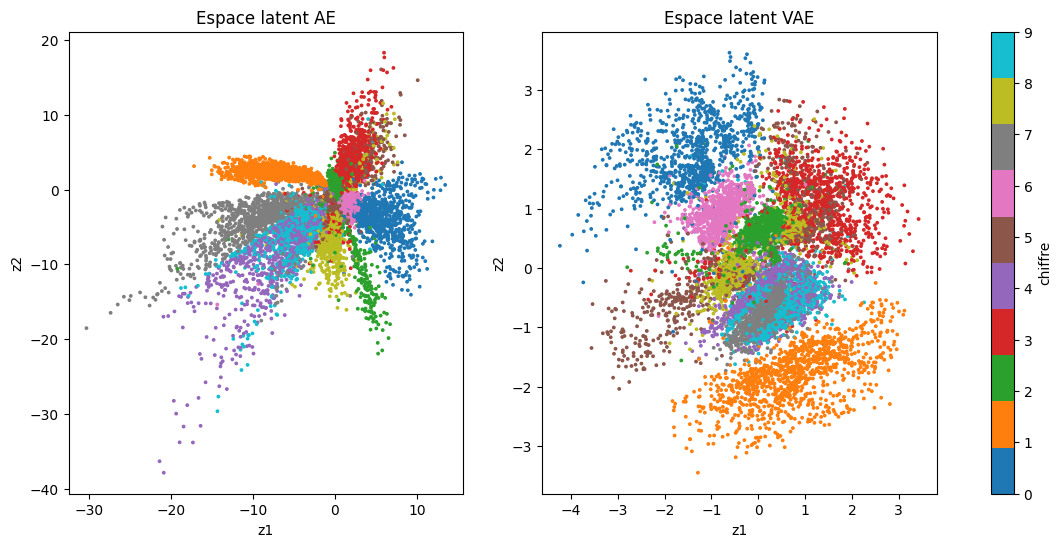

In [15]:
# 4.1 Espace latent coloré par chiffre
def get_latents(model, is_vae):
    """Retourne les coordonnées latentes (z pour l'AE, mu pour le VAE) et les labels du jeu de test."""
    zs, ys = [], []
    model.eval()
    with torch.no_grad():
        for x, y in test_dl:
            x = x.to(device)
            if is_vae:
                _, z, _ = model(x)       # VAE : on prend mu
            else:
                _, z = model(x)          # AE : z
            zs.append(z.cpu()); ys.append(y)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (m, v, t) in zip(ax, [(ae, False, "AE"), (vae, True, "VAE")]):
    z, y = get_latents(m, v)
    sc = a.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=3)
    a.set_title(f"Espace latent {t}"); a.set_xlabel("z1"); a.set_ylabel("z2")
fig.colorbar(sc, ax=ax, label="chiffre")
plt.savefig("latent_space_ae_vae.png", dpi=150); plt.show()

**Observations (espace latent)**
- **AE** : l'espace latent est très étalé et non centré (z1 d'environ -30 à +14, z2 d'environ -40 à +18). Les classes forment des **branches allongées** qui partent d'un centre très dense : le 0 à droite, le 1 à gauche, le 3 vers le haut, le 4 qui s'étire loin vers le bas. Au centre, plusieurs chiffres (4, 7, 9) se chevauchent fortement, et les zones entre les branches sont vides.
- **VAE** : le nuage est **compact et centré** près de (0, 0), avec z1 entre -4 et 3 environ et z2 entre -3.5 et 3.5, ce qui correspond à l'effet de la KL qui rapproche la distribution de N(0,1). Les classes sont plus regroupées et se touchent sans laisser de grands vides. Un chevauchement subsiste pour les chiffres proches (4/7/9, 5/8), ce qui est normal avec seulement 2 dimensions.

## 4.2 Décodage d'une grille de points de l'espace latent
On décode une grille 15×15 de points (z1, z2) et on assemble les images. Cela montre ce que le décodeur produit dans chaque zone du plan latent.

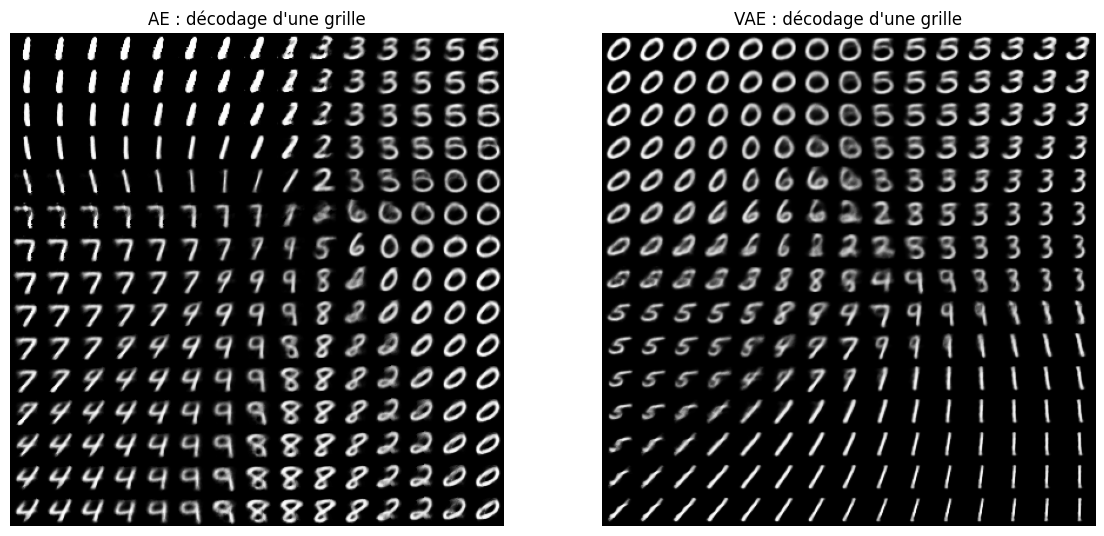

In [16]:
# 4.2 Décodage d'une grille de points de l'espace latent
def manifold(decoder, xlo, xhi, ylo, yhi, n=15):
    """Décode une grille n x n de points (z1, z2) et assemble les images en une seule."""
    canvas = np.zeros((28*n, 28*n))
    for i, yi in enumerate(np.linspace(yhi, ylo, n)):
        for j, xi in enumerate(np.linspace(xlo, xhi, n)):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            with torch.no_grad():
                canvas[i*28:(i+1)*28, j*28:(j+1)*28] = decoder(z).view(28, 28).cpu().numpy()
    return canvas

# AE : grille adaptée à la zone réellement occupée (percentiles 1 et 99)
z_ae, _ = get_latents(ae, False)
(xlo, ylo), (xhi, yhi) = np.percentile(z_ae, 1, axis=0), np.percentile(z_ae, 99, axis=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(manifold(ae.dec, xlo, xhi, ylo, yhi), cmap="gray"); ax[0].set_title("AE : décodage d'une grille"); ax[0].axis("off")
ax[1].imshow(manifold(vae.dec, -3, 3, -3, 3), cmap="gray");      ax[1].set_title("VAE : décodage d'une grille"); ax[1].axis("off")
plt.savefig("manifold_ae_vae.png", dpi=150); plt.show()

**Observations (décodage d'une grille)**
- **AE** : les coins de la grille donnent des chiffres nets (1 en haut à gauche, 5 en haut à droite, 4 en bas à gauche, 0 en bas à droite), mais les **transitions sont brusques** (par exemple de 1 à 3 puis 5 en haut) et la zone centrale donne des images floues et ambiguës (2, 8, 9 mal formés), là où les classes se chevauchent. Le décodeur ne sait pas bien quoi produire entre les amas.
- **VAE** : la grille montre des **transitions continues et progressives** d'un chiffre à l'autre (par exemple 0 → 5 → 3 en haut, 0 → 6 → 2 puis 8 / 9 au centre, 5 → 7 → 1 vers le bas). Tout point proche de (0, 0) décode un chiffre plausible : l'espace est continu et on peut y échantillonner.

## 4.3 Génération de nouveaux chiffres avec le VAE (latent=2)
On tire 16 vecteurs `z` au hasard dans N(0,1) et on les décode : ces chiffres n'existent pas dans MNIST.

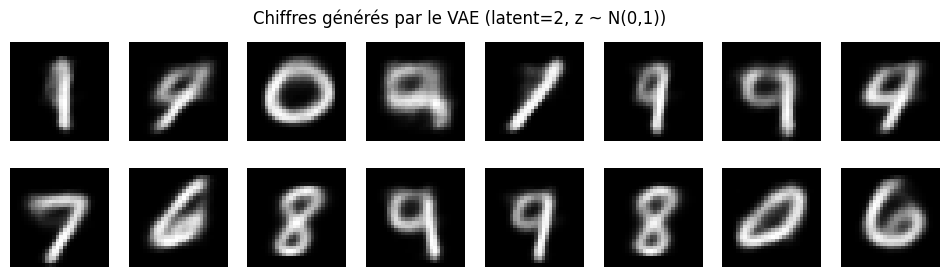

In [17]:
# 4.3 Génération : 16 chiffres tirés au hasard dans N(0,1) avec le VAE (latent=2)
with torch.no_grad():
    gen = vae.dec(torch.randn(16, 2, device=device)).view(-1, 28, 28).cpu()
fig, ax = plt.subplots(2, 8, figsize=(12, 3))
for i, a in enumerate(ax.flat):
    a.imshow(gen[i], cmap="gray"); a.axis("off")
plt.suptitle("Chiffres générés par le VAE (latent=2, z ~ N(0,1))")
plt.savefig("vae_generation_latent2.png", dpi=150); plt.show()

**Observations (génération)**
- Les chiffres tirés au hasard dans N(0,1) sont globalement reconnaissables (1, 9, 0, 7, 6, 8), mais plus flous que ceux du VAE à `latent=16`, et la diversité est limitée (beaucoup de 9 et de 8). Cela s'explique par la dimension latente 2, qui conserve peu d'information.
- Ces images n'existent pas dans MNIST : le VAE **génère** de nouvelles données, ce que l'AE ne peut pas faire correctement.

**Conclusion générale de la partie 1**
Un AE apprend à compresser et reconstruire : excellent pour la fidélité, mais son espace latent est irrégulier, avec des zones vides. Un VAE régularise cet espace (KL) : il perd un peu en netteté mais gagne un espace continu et centré, ce qui permet la génération. Augmenter la dimension latente (2 → 16) améliore la qualité des deux modèles.

---
# Partie 2 : GAN sur Abstract Art Gallery
Un **GAN** (réseau antagoniste génératif) met en compétition deux réseaux :
- le **générateur G** fabrique de fausses images à partir d'un bruit aléatoire `z` ;
- le **discriminateur D** essaie de distinguer les vraies images des fausses.

Ils progressent ensemble : D devient meilleur pour détecter les faux, G devient meilleur pour le tromper. L'objectif est que G produise de nouvelles images d'art abstrait ressemblant à celles du dataset.

# 5. Données : Abstract Art Gallery
## 5.1 Téléchargement du dataset
On télécharge le dataset Kaggle `bryanb/abstract-art-gallery` avec `kagglehub`.

In [18]:
# 5.1 Télécharger le dataset Abstract Art Gallery
!pip -q install kagglehub
import kagglehub, glob

path = kagglehub.dataset_download("bryanb/abstract-art-gallery")
print("Chemin du dataset :", path)

Using Colab cache for faster access to the 'abstract-art-gallery' dataset.
Chemin du dataset : /kaggle/input/abstract-art-gallery


## 5.2 Préparation des images
- Les images sont redimensionnées et recadrées en **64×64** pixels (taille standard pour un GAN convolutif simple, et rapide à entraîner).
- Elles sont normalisées dans **[-1, 1]** : le générateur finit par une activation `Tanh`, dont la sortie est justement dans [-1, 1].
- Un `Dataset` personnalisé lit tous les fichiers image du dossier, et un `DataLoader` les découpe en lots de 64.

In [19]:
# 5.2 Dataset personnalisé et DataLoader
from PIL import Image

class ArtDS(torch.utils.data.Dataset):
    """Charge toutes les images (jpg, jpeg, png) trouvées dans le dossier, y compris les sous-dossiers."""
    def __init__(self, root, tf):
        self.files = [f for e in ("jpg", "jpeg", "png")
                        for f in glob.glob(f"{root}/**/*.{e}", recursive=True)]
        self.tf = tf
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        return self.tf(Image.open(self.files[i]).convert("RGB"))

img_size = 64
tf_gan = transforms.Compose([
    transforms.Resize(img_size), transforms.CenterCrop(img_size),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)])      # pixels dans [-1, 1]

art_ds = ArtDS(path, tf_gan)
art_dl = DataLoader(art_ds, batch_size=64, shuffle=True, num_workers=2, drop_last=True)
print(len(art_ds), "images | forme d'un batch :", next(iter(art_dl)).shape)

2872 images | forme d'un batch : torch.Size([64, 3, 64, 64])


## 5.3 Exploration : quelques images originales

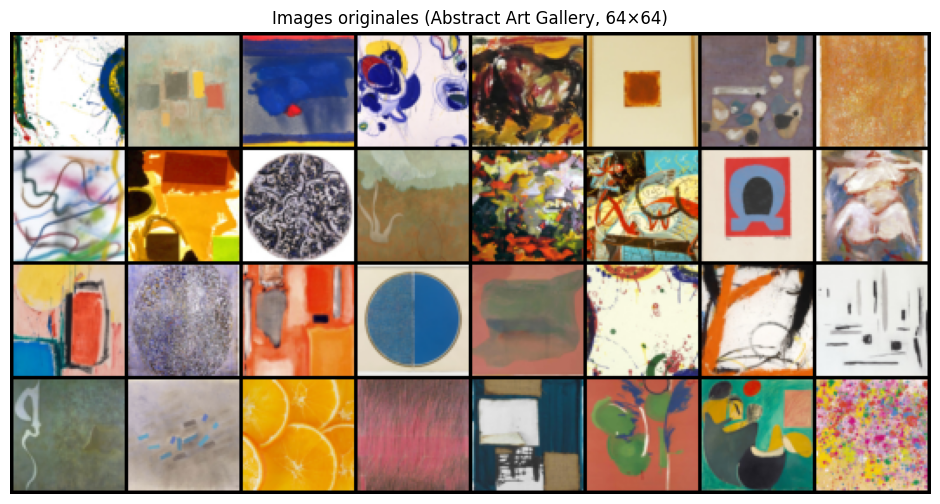

In [20]:
# 5.3 Afficher quelques images originales
from torchvision.utils import make_grid

batch = next(iter(art_dl))[:32]
plt.figure(figsize=(12, 6))
plt.imshow(make_grid(batch, nrow=8, normalize=True, value_range=(-1, 1)).permute(1, 2, 0))
plt.title("Images originales (Abstract Art Gallery, 64×64)"); plt.axis("off")
plt.savefig("art_originals.png", dpi=150); plt.show()

**Observations (données)**
- Le dataset contient **2872 images** d'art abstrait, redimensionnées en 64×64 RGB ; un batch a la forme `[64, 3, 64, 64]`.
- Les images sont **très variées** (palettes, styles, compositions, textures). C'est difficile à modéliser pour un GAN, surtout avec un dataset aussi petit (quelques milliers d'images seulement).

# 6. Modèles : générateur, discriminateur, perte et optimiseurs
## 6.1 Architecture du générateur et du discriminateur (DCGAN)
- **Générateur G** : transforme un bruit `z` (100 valeurs) en image 64×64×3. Il utilise des **convolutions transposées** qui doublent la taille à chaque couche (1×1 → 4×4 → 8×8 → 16×16 → 32×32 → 64×64), avec BatchNorm + ReLU, et une **Tanh** finale (sortie dans [-1, 1]).
- **Discriminateur D** : prend une image et sort un score « vrai / faux ». Il utilise des **convolutions** qui divisent la taille par 2 (64 → 32 → 16 → 8 → 4 → 1), avec BatchNorm + LeakyReLU. La sortie est un **logit** (pas de sigmoïde : elle est incluse dans la fonction de perte).

In [21]:
# 6.1 Définir le générateur et le discriminateur
nz = 100   # taille du vecteur de bruit

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        def up(i, o):   # bloc : double la taille de l'image
            return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),  # 4x4
            *up(512, 256), *up(256, 128), *up(128, 64),                                            # 32x32
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False), nn.Tanh())                             # 64x64, [-1,1]
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        def down(i, o):   # bloc : divise la taille de l'image par 2
            return [nn.Conv2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),   # 32x32
            *down(64, 128), *down(128, 256), *down(256, 512),                 # 4x4
            nn.Conv2d(512, 1, 4, 1, 0, bias=False))                           # 1 score (logit)
    def forward(self, x): return self.net(x).view(-1)

## 6.2 Initialisation, GPU, fonction de perte et optimiseurs
- **Initialisation** des poids selon N(0, 0.02), recommandée pour les GANs (DCGAN).
- **GPU** : les deux réseaux sont envoyés sur `device` (Tesla T4).
- **Perte** : entropie croisée binaire (`BCEWithLogitsLoss`). D doit sortir 1 pour les vraies images et 0 pour les fausses ; G veut que D classe ses images comme vraies.
- **Optimiseurs** : Adam (lr = 2e-4, β1 = 0.5), valeurs standard pour les GANs, un optimiseur par réseau.

In [22]:
# 6.2 Initialisation, GPU, perte, optimiseurs
def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

G = Generator().to(device); D = Discriminator().to(device)   # GPU
G.apply(init_weights); D.apply(init_weights)

criterion = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

# Vérification des formes
z = torch.randn(4, nz, 1, 1, device=device)
print("G(z) :", G(z).shape, "| D(G(z)) :", D(G(z)).shape)
print("Paramètres G :", sum(p.numel() for p in G.parameters()),
      "| D :", sum(p.numel() for p in D.parameters()))

G(z) : torch.Size([4, 3, 64, 64]) | D(G(z)) : torch.Size([4])
Paramètres G : 3576704 | D : 2765568


**Vérification** : `G(z)` produit bien des images `[4, 3, 64, 64]` et `D(G(z))` un score par image `[4]`. G compte 3 576 704 paramètres et D 2 765 568.

# 7. Entraînement du GAN
À chaque itération :
1. **Discriminateur** : on lui donne un lot de vraies images (cible 1) et un lot de fausses images produites par G (cible 0). Sa loss est la somme des deux erreurs. Les images fausses sont passées avec `detach()` pour ne pas mettre à jour G à cette étape.
2. **Générateur** : on lui fait générer des images, et on lui demande de tromper D (cible 1 pour ses propres images fausses).

On enregistre à chaque epoch :
- les loss de G et de D ;
- `D(x)` : sortie moyenne de D sur les **vraies** images (après sigmoïde) ;
- `D(G(z))` : sortie moyenne de D sur les **fausses** images.

Un équilibre sain est atteint quand `D(x)` et `D(G(z))` tendent vers ~0.5.
Tous les 10 epochs, on sauvegarde une grille d'images générées à partir du **même bruit fixe**, pour suivre l'évolution visuelle de G.

## 7.1 Pré-traitement rapide du dataset
Le `DataLoader` relisait et redimensionnait chaque image à chaque epoch (≈ 47 s par epoch). On prétraite donc **une seule fois** toutes les images (64×64, normalisées dans [-1, 1]) et on les garde **sur le GPU** : l'entraînement passe à ≈ 4 s par epoch. Le `DataLoader` de la partie 5 ne sert plus que pour l'affichage.

In [26]:
# Pré-traitement unique et rapide du dataset : toutes les images en 64x64, stockées sur le GPU
import numpy as np, time
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

def load_img(f, size=64):
    """Charge une image, la recadre en carré (centre) et la réduit à size x size."""
    img = Image.open(f)
    img.draft("RGB", (size*2, size*2))        # décodage JPEG directement réduit (gain de temps majeur)
    img = img.convert("RGB")
    w, h = img.size; s = min(w, h)
    left, top = (w - s)//2, (h - s)//2
    img = img.crop((left, top, left + s, top + s)).resize((size, size), Image.BILINEAR)
    return np.asarray(img)

t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    arrs = list(tqdm(ex.map(load_img, art_ds.files), total=len(art_ds.files)))
data_np = np.stack(arrs)                      # [N, 64, 64, 3] en uint8
np.save("art64.npy", data_np)                 # sauvegarde : rechargeable en 1 seconde
print(f"{len(data_np)} images prétraitées en {time.time()-t0:.0f}s")

# Conversion en tenseur PyTorch normalisé dans [-1, 1], placé sur le GPU
data = torch.from_numpy(data_np).permute(0, 3, 1, 2).float().div(255).sub(0.5).div(0.5).to(device)
print("Données en mémoire :", data.shape)     # [N, 3, 64, 64]

def art_dl_fast(bs=64):
    """Remplace le DataLoader : mélange et découpe en batches directement sur le GPU."""
    perm = torch.randperm(len(data), device=device)
    for i in range(0, len(data) - bs + 1, bs):
        yield data[perm[i:i+bs]]

100%|██████████| 2872/2872 [00:21<00:00, 130.68it/s]


2872 images prétraitées en 22s
Données en mémoire : torch.Size([2872, 3, 64, 64])


## 7.2 Boucle d'entraînement (150 epochs)

In [27]:
# Entraînement du GAN
import time
from torchvision.utils import save_image

fixed_noise = torch.randn(64, nz, 1, 1, device=device)    # même bruit à chaque suivi visuel
G_losses, D_losses, D_real, D_fake = [], [], [], []
epochs = 150
t0 = time.time()

for ep in range(epochs):
    lG = lD = dr = df = 0; nb = 0
    for real in art_dl_fast():
        real = real.to(device); b = real.size(0)
        ones = torch.ones(b, device=device); zeros = torch.zeros(b, device=device)

        # 1) Discriminateur : vrai -> 1, faux -> 0
        noise = torch.randn(b, nz, 1, 1, device=device)
        fake = G(noise)
        out_r, out_f = D(real), D(fake.detach())
        lossD = criterion(out_r, ones) + criterion(out_f, zeros)
        optD.zero_grad(); lossD.backward(); optD.step()

        # 2) Générateur : veut que D classe ses faux comme vrais
        lossG = criterion(D(fake), ones)
        optG.zero_grad(); lossG.backward(); optG.step()

        lG += lossG.item(); lD += lossD.item()
        dr += torch.sigmoid(out_r).mean().item(); df += torch.sigmoid(out_f).mean().item(); nb += 1

    # moyennes sur l'epoch (courbes plus lisibles qu'une seule valeur de batch)
    G_losses.append(lG/nb); D_losses.append(lD/nb); D_real.append(dr/nb); D_fake.append(df/nb)

    if (ep+1) % 10 == 0 or ep == 0:
        print(f"Epoch {ep+1:3d}/{epochs} | D {D_losses[-1]:.3f} | G {G_losses[-1]:.3f} | "
              f"D(x) {D_real[-1]:.2f} | D(G(z)) {D_fake[-1]:.2f} | {time.time()-t0:.0f}s")
        with torch.no_grad(): samples = G(fixed_noise).cpu()
        save_image(samples, f"gen_epoch_{ep+1:03d}.png", normalize=True, value_range=(-1, 1), nrow=8)

Epoch   1/150 | D 0.885 | G 4.325 | D(x) 0.77 | D(G(z)) 0.23 | 4s
Epoch  10/150 | D 0.472 | G 4.878 | D(x) 0.85 | D(G(z)) 0.15 | 40s
Epoch  20/150 | D 0.712 | G 4.279 | D(x) 0.79 | D(G(z)) 0.20 | 77s
Epoch  30/150 | D 0.519 | G 4.572 | D(x) 0.82 | D(G(z)) 0.18 | 116s
Epoch  40/150 | D 0.660 | G 4.428 | D(x) 0.79 | D(G(z)) 0.22 | 153s
Epoch  50/150 | D 0.487 | G 3.819 | D(x) 0.82 | D(G(z)) 0.18 | 192s
Epoch  60/150 | D 0.490 | G 4.161 | D(x) 0.83 | D(G(z)) 0.17 | 229s
Epoch  70/150 | D 0.347 | G 4.762 | D(x) 0.87 | D(G(z)) 0.13 | 267s
Epoch  80/150 | D 0.239 | G 4.490 | D(x) 0.90 | D(G(z)) 0.10 | 305s
Epoch  90/150 | D 0.263 | G 4.782 | D(x) 0.90 | D(G(z)) 0.10 | 343s
Epoch 100/150 | D 0.249 | G 4.478 | D(x) 0.90 | D(G(z)) 0.10 | 381s
Epoch 110/150 | D 0.520 | G 4.488 | D(x) 0.83 | D(G(z)) 0.17 | 419s
Epoch 120/150 | D 0.311 | G 4.422 | D(x) 0.88 | D(G(z)) 0.12 | 457s
Epoch 130/150 | D 0.198 | G 4.721 | D(x) 0.92 | D(G(z)) 0.08 | 495s
Epoch 140/150 | D 0.167 | G 4.561 | D(x) 0.93 | D(G(

---
# 8. Évaluation du GAN
## 8.1 Courbes d'entraînement
**Remarque :** la KL divergence est propre au VAE et n'existe pas dans un GAN classique. On évalue donc le GAN avec les loss du générateur et du discriminateur, ainsi que les sorties du discriminateur D(x) sur les vraies images et D(G(z)) sur les fausses.

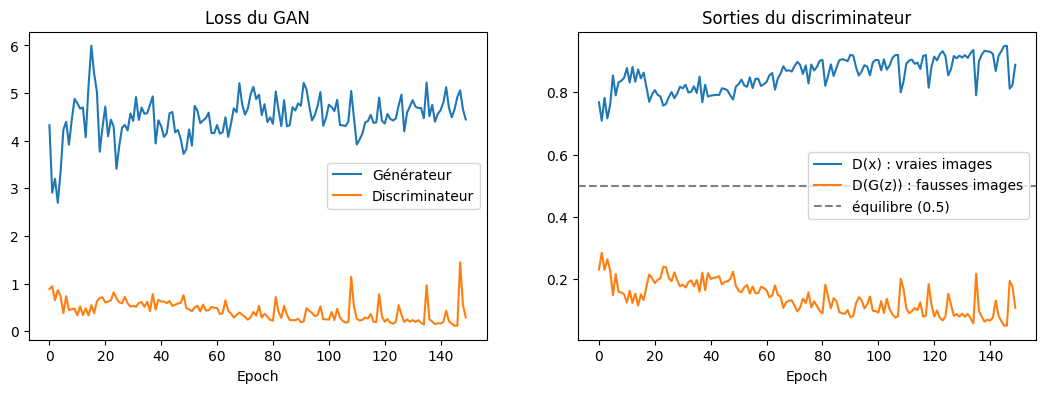

In [29]:
# Courbes d'entraînement du GAN
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(G_losses, label="Générateur"); ax[0].plot(D_losses, label="Discriminateur")
ax[0].set_xlabel("Epoch"); ax[0].set_title("Loss du GAN"); ax[0].legend()
ax[1].plot(D_real, label="D(x) : vraies images"); ax[1].plot(D_fake, label="D(G(z)) : fausses images")
ax[1].axhline(0.5, ls="--", c="gray", label="équilibre (0.5)")
ax[1].set_xlabel("Epoch"); ax[1].set_title("Sorties du discriminateur"); ax[1].legend()
plt.savefig("curves_gan.png", dpi=150); plt.show()

torch.save(G.state_dict(), "generator.pth")     # sauvegarde du générateur

**Conclusion sur les courbes**
- La loss du générateur reste stable autour de 4.5 pendant les 150 epochs : l'entraînement n'a ni divergé ni subi d'effondrement.
- D(x) augmente (0.77 → ~0.9) et D(G(z)) diminue (0.23 → ~0.1) : le discriminateur prend progressivement l'avantage sans empêcher le générateur d'apprendre. L'équilibre théorique (0.5) n'est pas atteint.
- La loss d'un GAN ne mesure pas la qualité des images (les deux réseaux évoluent en même temps) : l'évaluation visuelle est indispensable.

## 8.2 Évolution de la qualité des images pendant l'entraînement

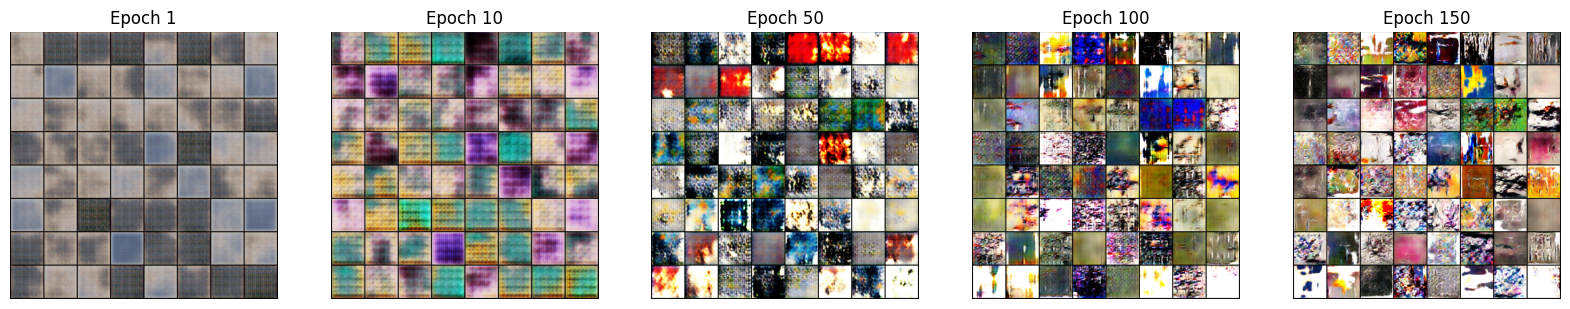

In [30]:
# Images générées avec le même bruit fixe, à différentes epochs
import matplotlib.image as mpimg
epochs_show = [1, 10, 50, 100, 150]
fig, ax = plt.subplots(1, len(epochs_show), figsize=(4*len(epochs_show), 4.4))
for a, e in zip(ax, epochs_show):
    a.imshow(mpimg.imread(f"gen_epoch_{e:03d}.png")); a.set_title(f"Epoch {e}"); a.axis("off")
plt.savefig("gan_progression.png", dpi=150, bbox_inches="tight"); plt.show()

## 8.3 Génération de nouvelles images et comparaison avec les originales

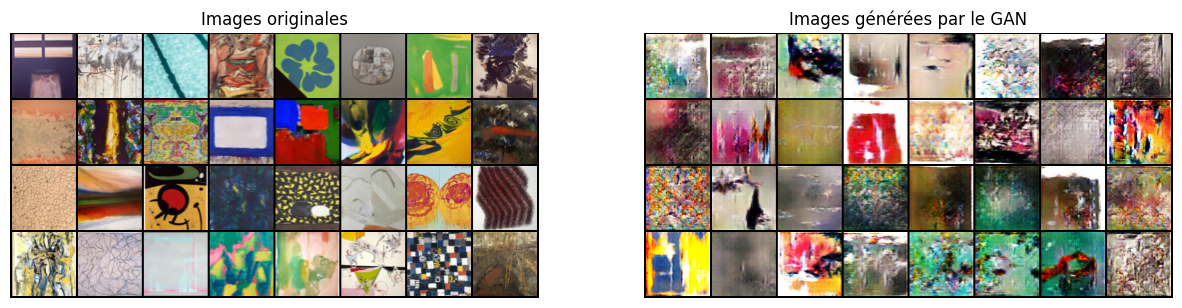

In [31]:
# 32 images originales (au hasard) contre 32 images générées à partir de bruit aléatoire
G.eval()
with torch.no_grad():
    fake = G(torch.randn(32, nz, 1, 1, device=device)).cpu()
real = data[torch.randperm(len(data), device=device)[:32]].cpu()

fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
for a, imgs, t in zip(ax, [real, fake], ["Images originales", "Images générées par le GAN"]):
    grid = make_grid(imgs, nrow=8, normalize=True, value_range=(-1, 1))
    a.imshow(grid.permute(1, 2, 0)); a.set_title(t); a.axis("off")
plt.savefig("real_vs_fake.png", dpi=150, bbox_inches="tight"); plt.show()

**Comparaison : images originales vs images générées**
- **Points forts :** le GAN reproduit les palettes de couleurs et les textures globales de l'art abstrait, avec une bonne diversité (pas de mode collapse).
- **Limites :** les formes nettes et structurées (cercles, aplats, motifs géométriques) des originales sont absentes. Les images générées présentent du bruit haute fréquence et des motifs répétitifs.
- **Causes probables :** dataset petit (2 872 images), faible résolution (64×64), architecture DCGAN simple et discriminateur qui domine en fin d'entraînement.
- **Pistes d'amélioration :** plus d'epochs, label smoothing, augmentation de données, architectures plus avancées (WGAN-GP, StyleGAN).

# Synthèse personnelle
Dans ce lab, j'ai appris à construire avec PyTorch trois familles de modèles génératifs.
- **Auto-encodeur :** compression et reconstruction. La dimension de l'espace latent détermine la qualité (loss test 0.037 avec 2 dimensions, 0.010 avec 16).
- **VAE :** l'encodeur produit une distribution, et la KL divergence régularise l'espace latent. Cela permet de générer de nouvelles images, au prix de reconstructions plus floues.
- **GAN :** deux réseaux en compétition. L'entraînement est plus délicat : la loss ne reflète pas la qualité et il faut surveiller D(x) et D(G(z)).
- **Difficultés rencontrées :** temps d'entraînement très long à cause du chargement des images (résolu en prétraitant le dataset une seule fois et en le gardant sur le GPU).